In [43]:
import pandas as pd

In [44]:
train = pd.read_csv("Dataset/AB_NYC_2019.csv")
train.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [45]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [46]:
train.describe(include="all")

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,48879,4.889500e+04,48874,48895,48895,48895.000000,48895.000000,48895,48895.000000,48895.000000,48895.000000,38843,38843.000000,48895.000000,48895.000000
unique,NaN,47905,NaN,11452,5,221,NaN,NaN,3,NaN,NaN,NaN,1764,NaN,NaN,NaN
top,NaN,Hillside Hotel,NaN,Michael,Manhattan,Williamsburg,NaN,NaN,Entire home/apt,NaN,NaN,NaN,2019-06-23,NaN,NaN,NaN
freq,NaN,18,NaN,417,21661,3920,NaN,NaN,25409,NaN,NaN,NaN,1413,NaN,NaN,NaN
mean,1.901714e+07,NaN,6.762001e+07,NaN,NaN,NaN,40.728949,-73.952170,NaN,152.720687,7.029962,23.274466,NaN,1.373221,7.143982,112.781327
std,1.098311e+07,NaN,7.861097e+07,NaN,NaN,NaN,0.054530,0.046157,NaN,240.154170,20.510550,44.550582,NaN,1.680442,32.952519,131.622289
min,2.539000e+03,NaN,2.438000e+03,NaN,NaN,NaN,40.499790,-74.244420,NaN,0.000000,1.000000,0.000000,NaN,0.010000,1.000000,0.000000
25%,9.471945e+06,NaN,7.822033e+06,NaN,NaN,NaN,40.690100,-73.983070,NaN,69.000000,1.000000,1.000000,NaN,0.190000,1.000000,0.000000
50%,1.967728e+07,NaN,3.079382e+07,NaN,NaN,NaN,40.723070,-73.955680,NaN,106.000000,3.000000,5.000000,NaN,0.720000,1.000000,45.000000
75%,2.915218e+07,NaN,1.074344e+08,NaN,NaN,NaN,40.763115,-73.936275,NaN,175.000000,5.000000,24.000000,NaN,2.020000,2.000000,227.000000


In [47]:
missing_values = train.isnull().sum()
missing_values[missing_values > 0]

name                    16
host_name               21
last_review          10052
reviews_per_month    10052
dtype: int64

In [48]:
train.duplicated().sum()

np.int64(0)

In [49]:
less=missing_values[missing_values < (len(train) * 0.75)].index

In [50]:
# Contoh mengisi nilai yang hilang dengan median untuk kolom numerik
numeric_features = train[less].select_dtypes(include=['number']).columns
train[numeric_features] = train[numeric_features].fillna(train[numeric_features].median())

In [51]:
# Contoh mengisi nilai yang hilang dengan mode untuk kolom kategori 
kategorical_features = train[less].select_dtypes(include=['object']).columns

for column in kategorical_features:
    train[column] = train[column].fillna(train[column].mode()[0])

In [52]:
missing_values = train.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

In [53]:
train.shape

(48895, 16)

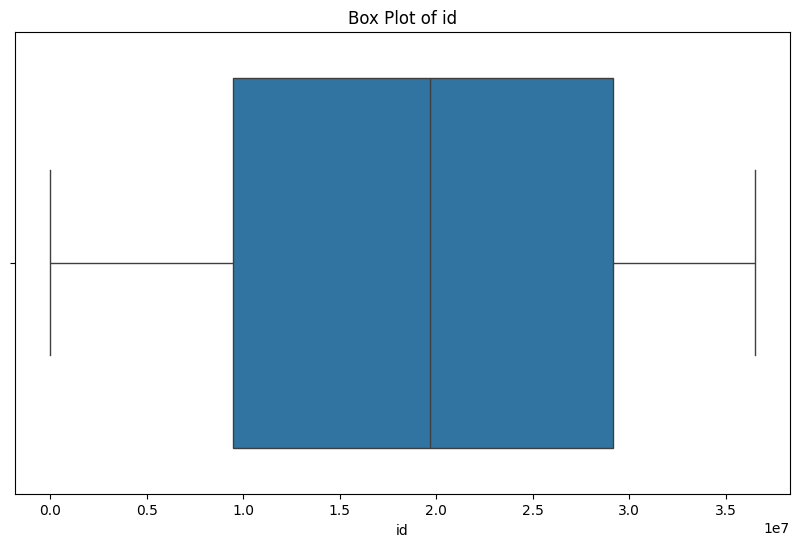

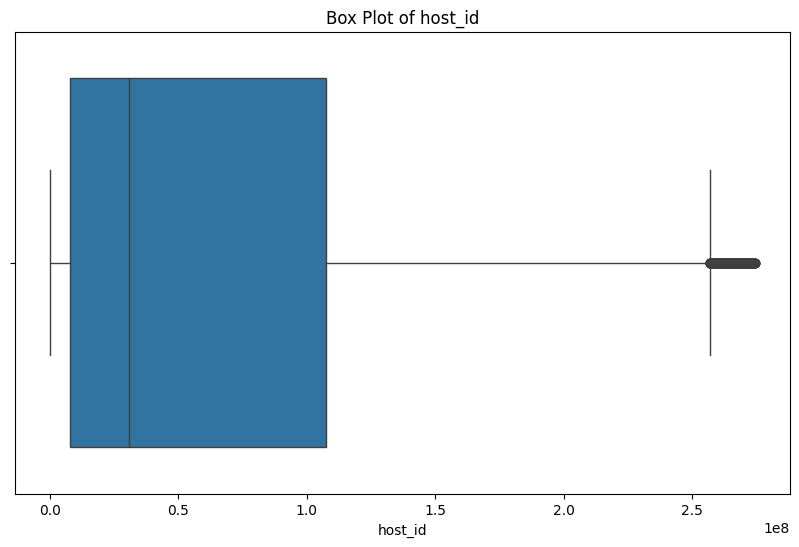

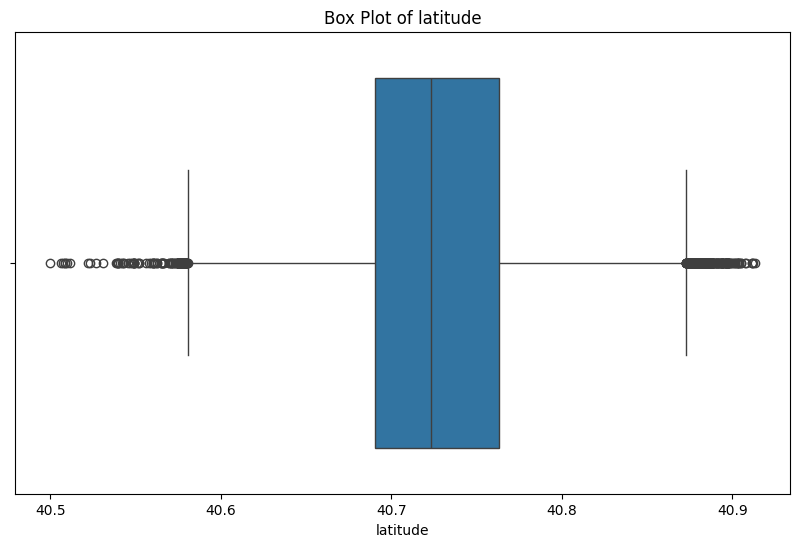

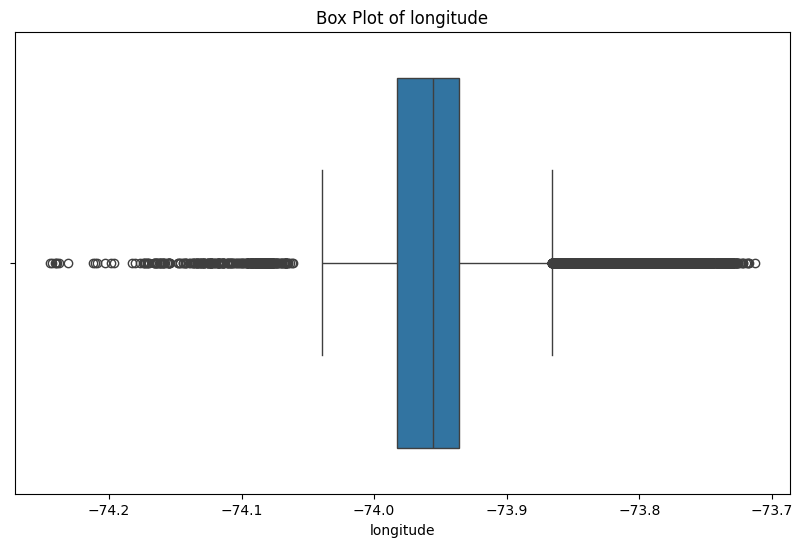

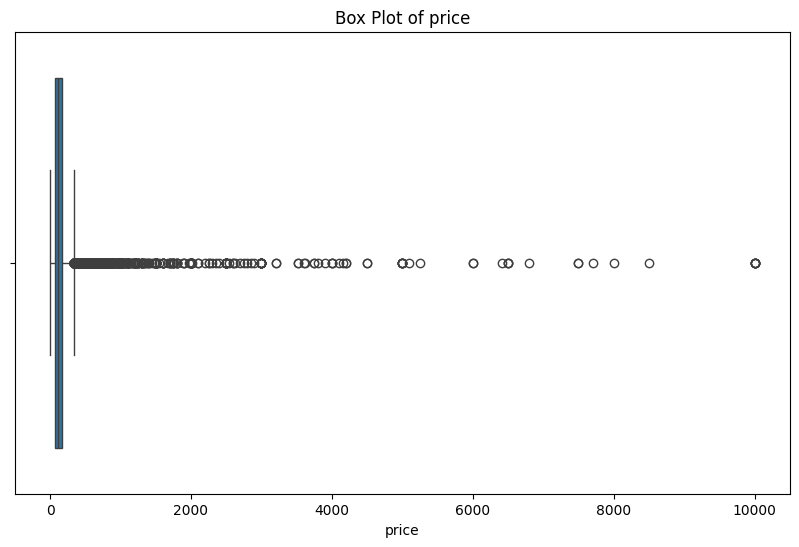

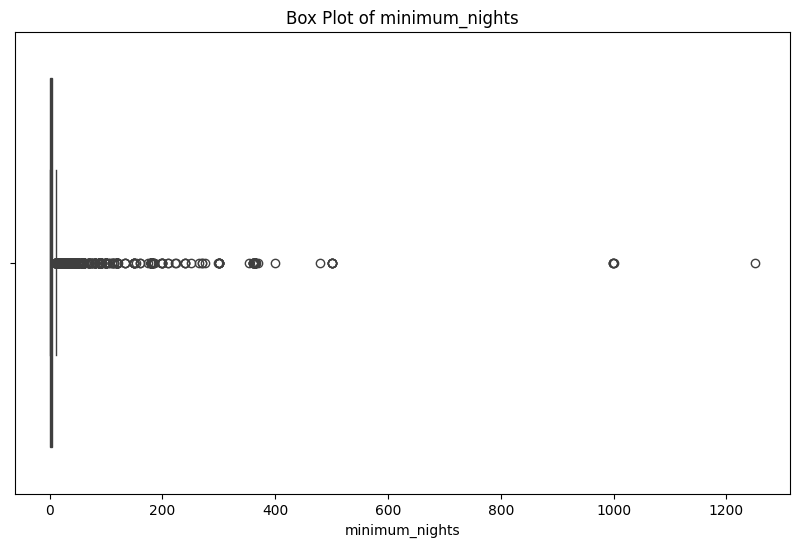

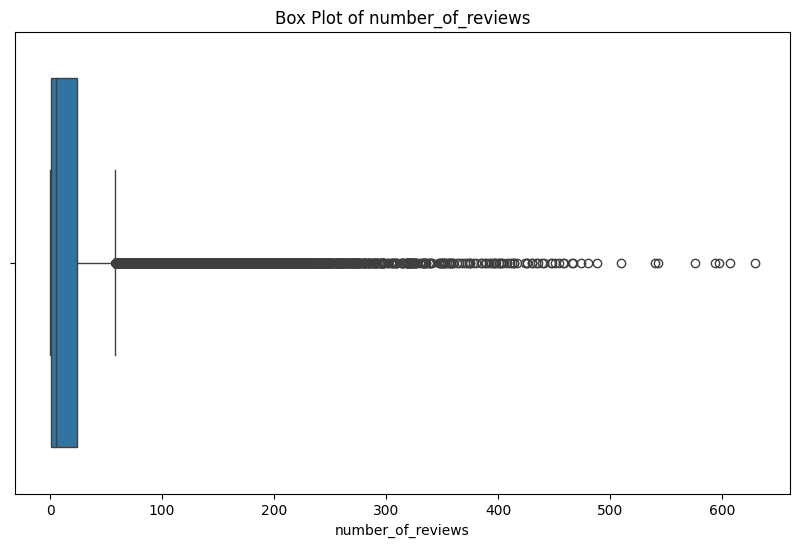

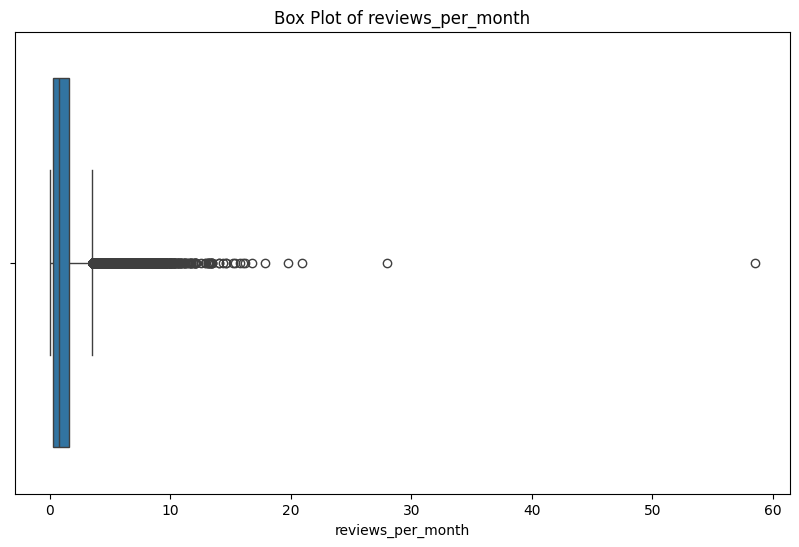

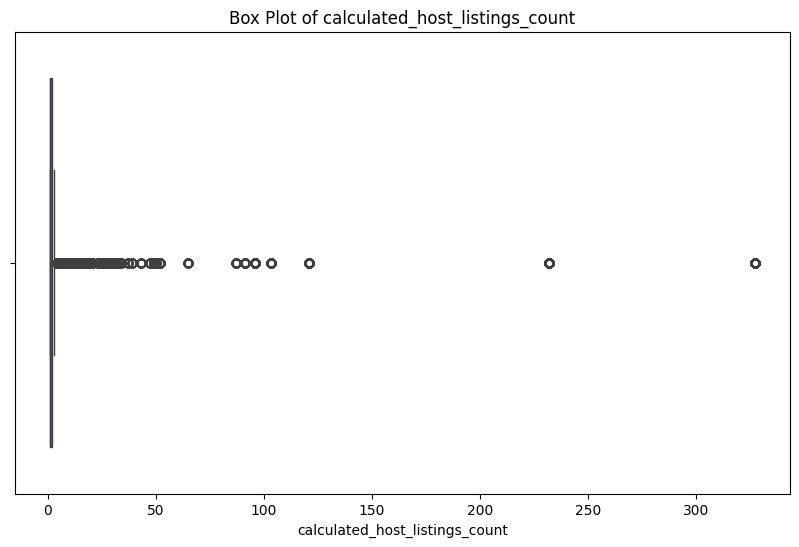

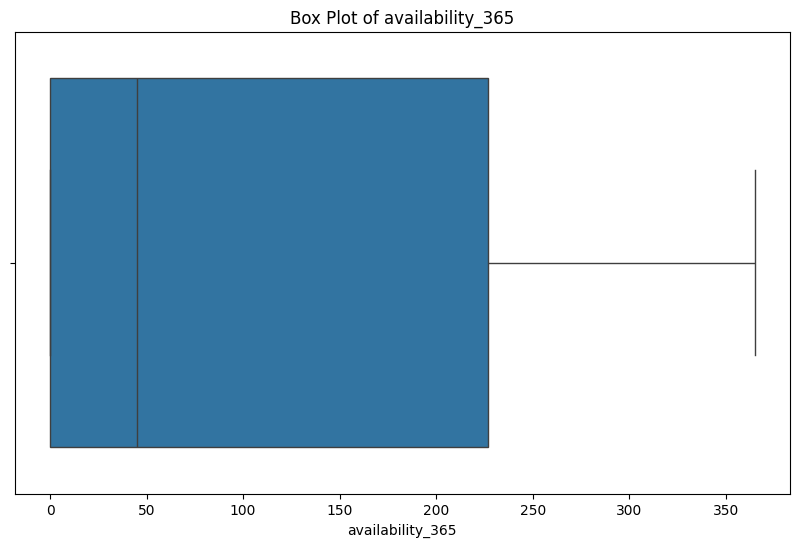

In [54]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

for feature in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=train[feature])
    plt.title(f'Box Plot of {feature}')
    plt.show()

In [55]:
# Contoh sederhana untuk mengidentifikasi outliners menggunakan IQR 
Q1 = train[numeric_features].quantile(0.25)
Q3 = train[numeric_features].quantile(0.75)
IQR = Q3 - Q1

In [56]:
# Filter dataframe untuk hanya menyimpan baris yang tidak mengandung ourliers pada kolom numerik
condition = ~((train[numeric_features] < (Q1 - 1.5 * IQR)) |
              (train[numeric_features] > (Q3 + 1.5 * IQR))
             ).any(axis=1)
df_filtered_numeric = train.loc[condition, numeric_features]

# menggabungkan kembali dengan kolom  kategorikal
categorical_features = train.select_dtypes(include=['object']).columns
train = pd.concat([df_filtered_numeric, train.loc[condition, categorical_features]], axis=1)

In [57]:
from sklearn.preprocessing import StandardScaler

# Standardisasi fitur numerik
scaler = StandardScaler()
train[numeric_features] = scaler.fit_transform(train[numeric_features])

Text(0.5, 1.0, 'Histogram Sebelum Standarisasi')

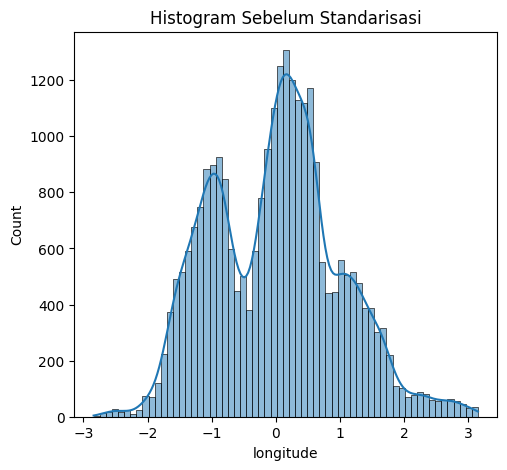

In [58]:
# Histogram Sebelum Standarisasi
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot (train[numeric_features[3]], kde=True)
plt.title("Histogram Sebelum Standarisasi") 

Text(0.5, 1.0, 'Histogram Setelah Standardisasi')

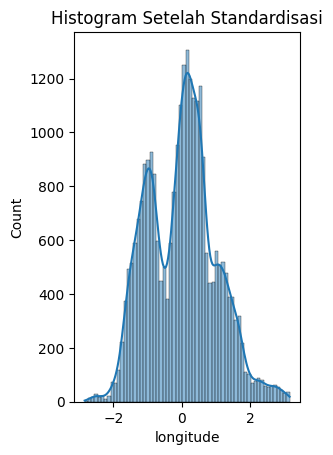

In [59]:
# Histogram Setelah Standardisasi
plt.subplot(1, 2, 2)
sns.histplot(train[numeric_features[3]], kde=True)
plt.title("Histogram Setelah Standardisasi")

In [60]:
category_features = train.select_dtypes(include=['object']).columns
train[category_features]

,name,host_name,neighbourhood_group,neighbourhood,room_type,last_review
1,Skylit Midtown Castle,Jennifer,Manhattan,Midtown,Entire home/apt,2019-05-21
2,THE VILLAGE OF HARLEM....NEW YORK !,Elisabeth,Manhattan,Harlem,Private room,2019-06-23
4,Entire Apt: Spacious Studio/Loft by central park,Laura,Manhattan,East Harlem,Entire home/apt,2018-11-19
10,Beautiful 1br on Upper West Side,Lena,Manhattan,Upper West Side,Entire home/apt,2019-06-22
19,Huge 2 BR Upper East Cental Park,Sing,Manhattan,East Harlem,Entire home/apt,2019-06-23
...,...,...,...,...,...,...
48887,Garden Jewel Apartment in Williamsburg New York,Melki,Brooklyn,Williamsburg,Entire home/apt,2019-06-23
48890,Charming one bedroom - newly renovated rowhouse,Sabrina,Brooklyn,Bedford-Stuyvesant,Private room,2019-06-23
48891,Affordable room in Bushwick/East Williamsburg,Marisol,Brooklyn,Bushwick,Private room,2019-06-23
48892,Sunny Studio at Historical Neighborhood,Ilgar & Aysel,Manhattan,Harlem,Entire home/apt,2019-06-23


In [61]:
train.shape

(27049, 16)

In [62]:
df_one_hot = pd.get_dummies(train, columns=category_features)
df_one_hot

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,...,last_review_2019-06-29,last_review_2019-06-30,last_review_2019-07-01,last_review_2019-07-02,last_review_2019-07-03,last_review_2019-07-04,last_review_2019-07-05,last_review_2019-07-06,last_review_2019-07-07,last_review_2019-07-08
1,-1.764540,-0.812848,0.465555,-0.915604,1.543308,-0.984776,2.702817,-0.472621,1.389437,2.708473,...,False,False,False,False,False,False,False,False,False,False
2,-1.764438,-0.812820,1.518183,0.533295,0.419874,0.024496,-0.734384,-0.005418,-0.457569,2.801183,...,False,False,False,False,False,False,False,False,False,False
4,-1.764305,-0.812780,1.318488,0.460971,-0.628664,3.556946,-0.046944,-0.857376,-0.457569,-0.582728,...,False,False,False,False,False,False,False,False,False,False
10,-1.764278,-0.812772,1.406840,-0.281646,0.195188,1.033767,3.313875,-0.403914,-0.457569,-0.527102,...,False,False,False,False,False,False,False,False,False,False
19,-1.764040,-0.812611,1.286947,0.297291,1.019039,2.043039,-0.734384,-0.005418,1.389437,1.725748,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48887,1.773008,2.461151,-0.319167,0.522913,0.719457,-0.984776,-0.734384,-0.005418,3.236444,2.801183,...,False,False,False,False,False,False,False,False,False,False
48890,1.773154,-0.683629,-0.961194,0.254727,-0.778455,-0.480140,-0.734384,-0.005418,1.389437,-0.499289,...,False,False,False,False,False,False,False,False,False,False
48891,1.773192,-0.709723,-0.518292,0.835394,-1.227829,0.529132,-0.734384,-0.005418,1.389437,-0.248972,...,False,False,False,False,False,False,False,False,False,False
48892,1.773229,-0.444012,1.627056,0.299021,-0.104395,3.556946,-0.734384,-0.005418,-0.457569,-0.332411,...,False,False,False,False,False,False,False,False,False,False


In [63]:
from sklearn.preprocessing import LabelEncoder

 # Inisialisasi LabelEncoder
label_encoder = LabelEncoder()
df_lencoder = pd.DataFrame(train)

for col in category_features:
    df_lencoder[col] = label_encoder.fit_transform(train[col])
    
# Menampilkan hasil
df_lencoder

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,name,host_name,neighbourhood_group,neighbourhood,room_type,last_review
1,-1.764540,-0.812848,0.465555,-0.915604,1.543308,-0.984776,2.702817,-0.472621,1.389437,2.708473,20748,3405,2,73,0,1634
2,-1.764438,-0.812820,1.518183,0.533295,0.419874,0.024496,-0.734384,-0.005418,-0.457569,2.801183,24384,2070,2,56,1,1667
4,-1.764305,-0.812780,1.318488,0.460971,-0.628664,3.556946,-0.046944,-0.857376,-0.457569,-0.582728,10628,4203,2,38,0,1451
10,-1.764278,-0.812772,1.406840,-0.281646,0.195188,1.033767,3.313875,-0.403914,-0.457569,-0.527102,2683,4275,2,109,0,1666
19,-1.764040,-0.812611,1.286947,0.297291,1.019039,2.043039,-0.734384,-0.005418,1.389437,1.725748,12697,6860,2,38,0,1667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48887,1.773008,2.461151,-0.319167,0.522913,0.719457,-0.984776,-0.734384,-0.005418,3.236444,2.801183,11278,5023,1,115,0,1667
48890,1.773154,-0.683629,-0.961194,0.254727,-0.778455,-0.480140,-0.734384,-0.005418,1.389437,-0.499289,6390,6403,1,5,1,1667
48891,1.773192,-0.709723,-0.518292,0.835394,-1.227829,0.529132,-0.734384,-0.005418,1.389437,-0.248972,1608,4811,1,15,1,1667
48892,1.773229,-0.444012,1.627056,0.299021,-0.104395,3.556946,-0.734384,-0.005418,-0.457569,-0.332411,23697,3045,2,56,0,1667


In [64]:
#Menghitung jumlah dan persantase missing values di setiap kolom
missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) * 100

missing_data = pd.DataFrame({
    'Missing Values' : missing_values,
    'Percentage' : missing_percentage
}).sort_values(by='Missing Values', ascending=False)

missing_data[missing_data['Missing Values'] > 0] #Menampilkan kolom dengan missing values

,Missing Values,Percentage


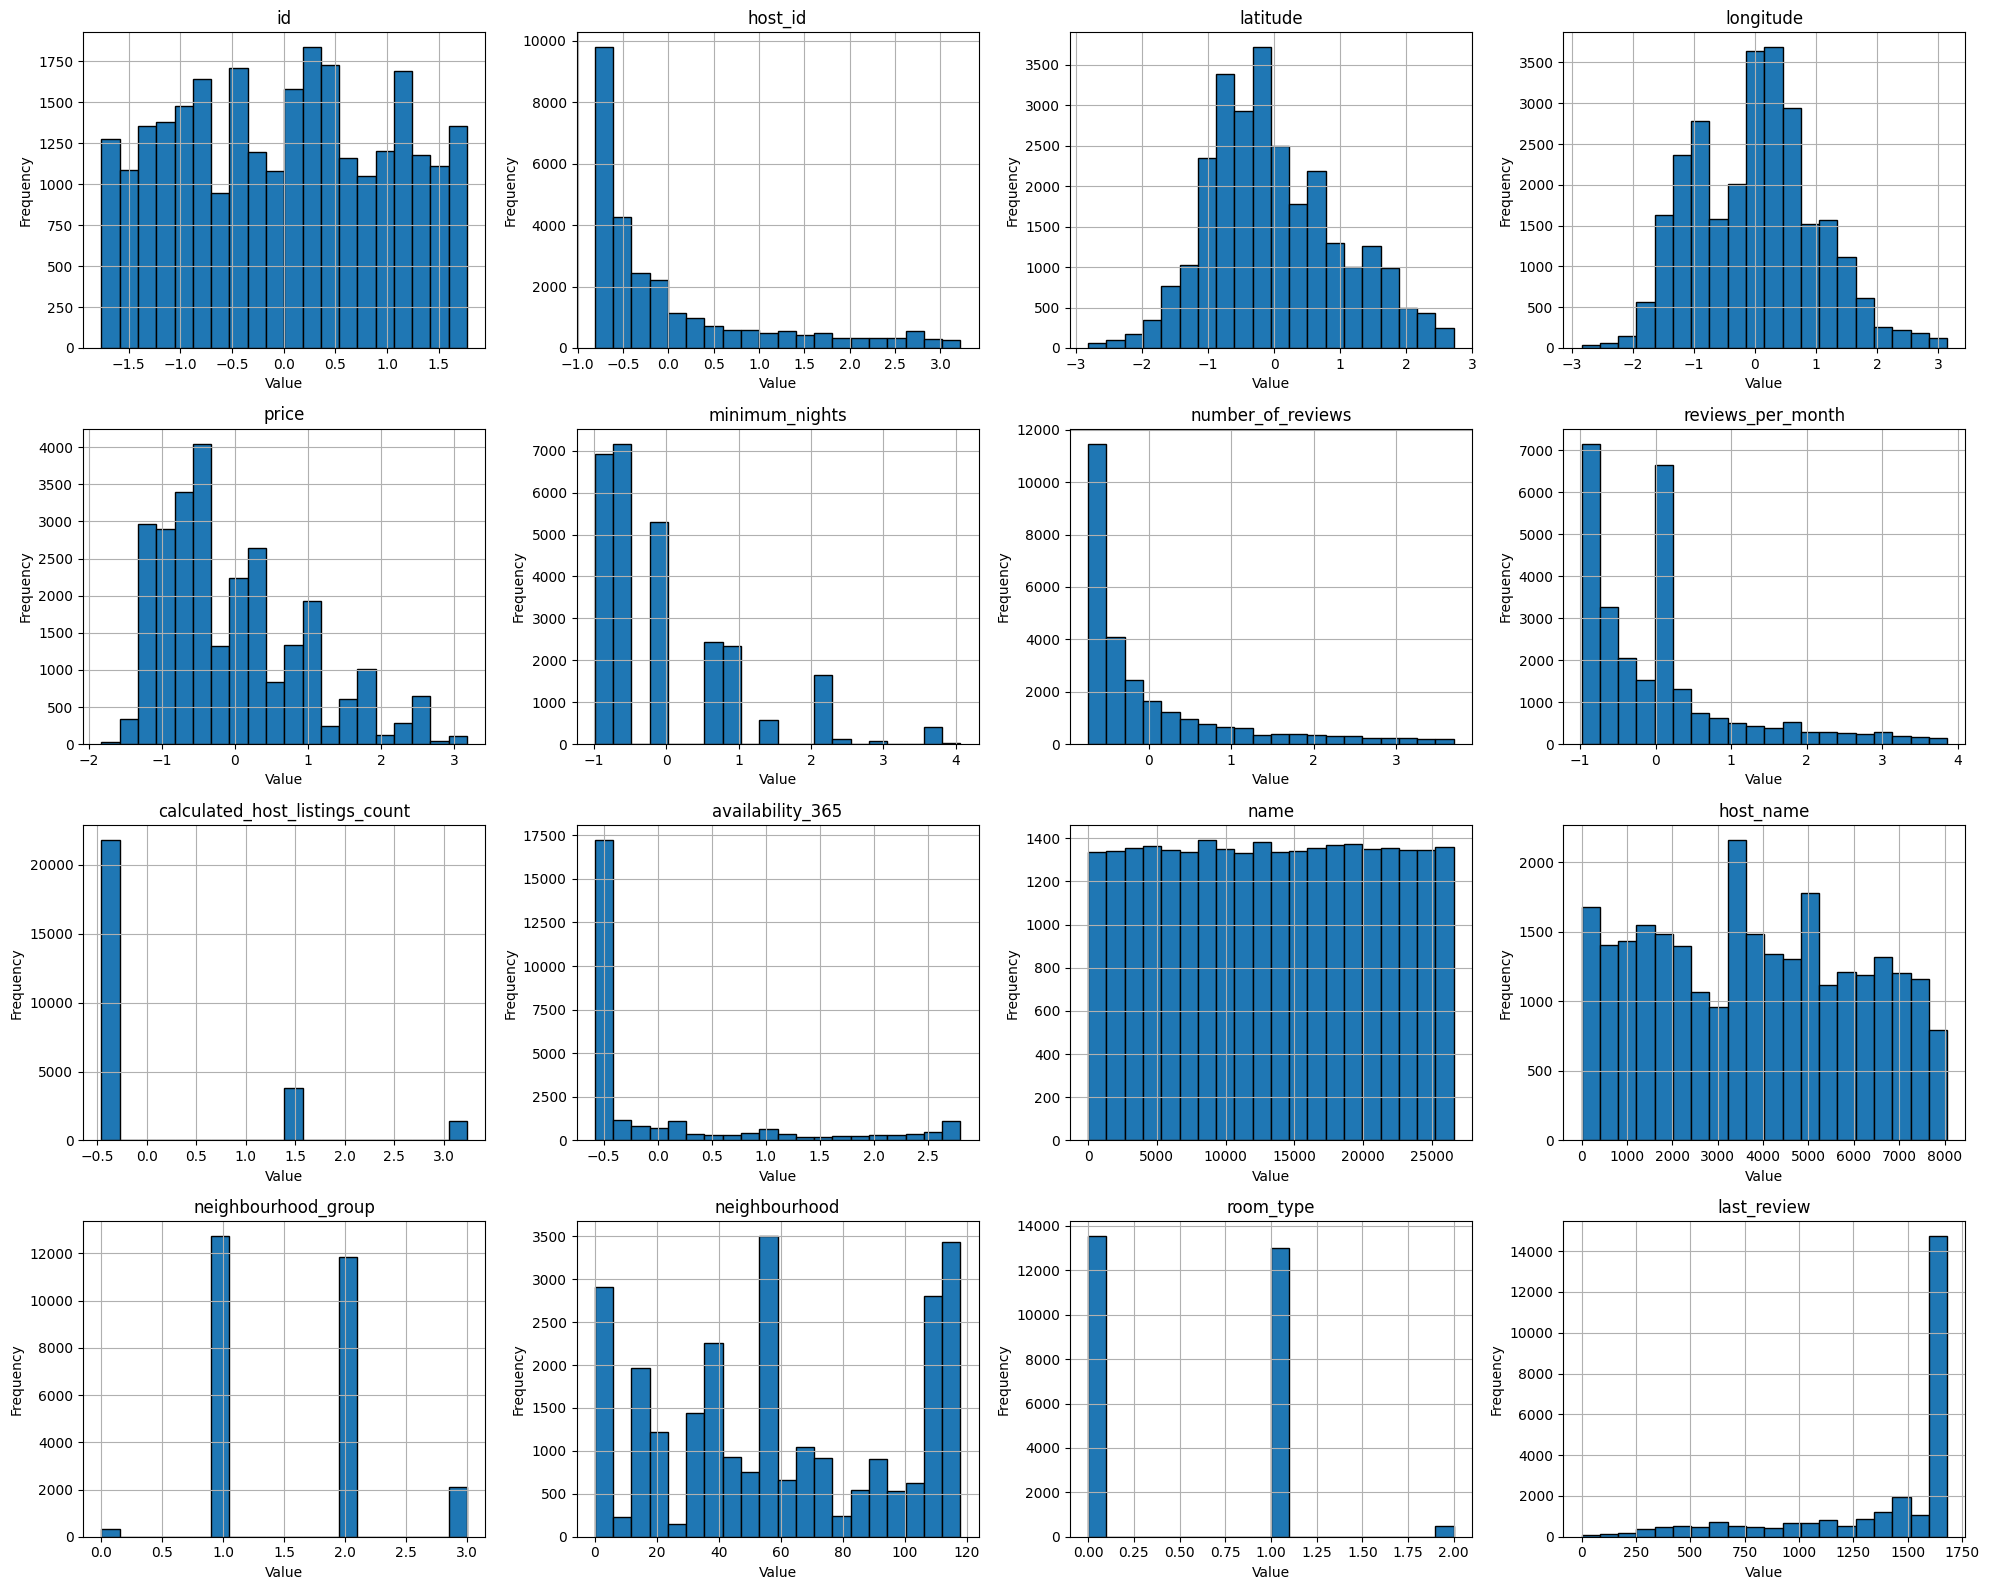

In [65]:
# Menghitung jumlah variabel
num_vars = df_lencoder.shape[1]

# Menentukan jumlah baris dan kolom untuk grid subplot
n_cols = 4 # Jumlah kolom yang diinginkan
n_rows = -(-num_vars // n_cols) # Ceiling division untuk menentukan jumlah baris

# Membuat subplot
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))

# Flatten axes array untuk memudahkan iterasi jika diperlukan 
axes = axes.flatten()

# Plot setiap variabel
for i, column in enumerate(df_lencoder.columns):
    df_lencoder[column].hist(ax=axes[i], bins=20, edgecolor='black')
    axes[i].set_title(column)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

# Menghapus subplot yang tidak terpakai (jika ada)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# Menyesuaikan layout agar lebih rapi
plt.tight_layout()
plt.show()


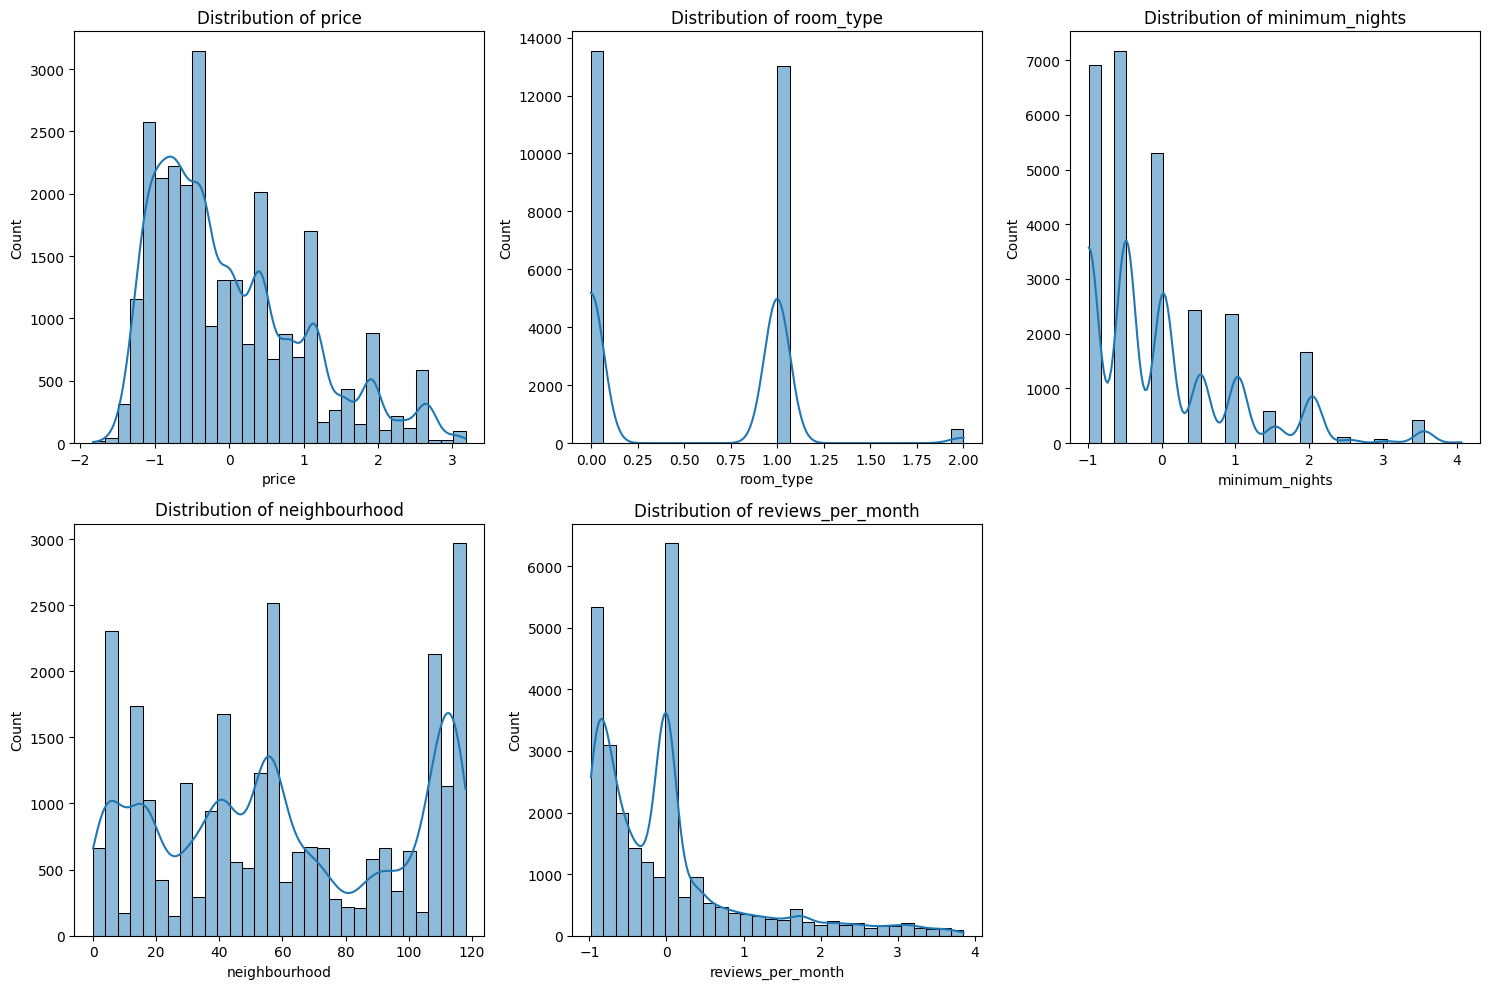

In [66]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualisasi distribusi data untuk beberapa kolom
columns_to_plot = [ 'price', 'room_type', 'minimum_nights', 'neighbourhood', 'reviews_per_month']

plt.figure(figsize=(15, 10))
for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df_lencoder[column], kde=True, bins=30)
    plt.title(f'Distribution of {column}')

plt.tight_layout()
plt.show()

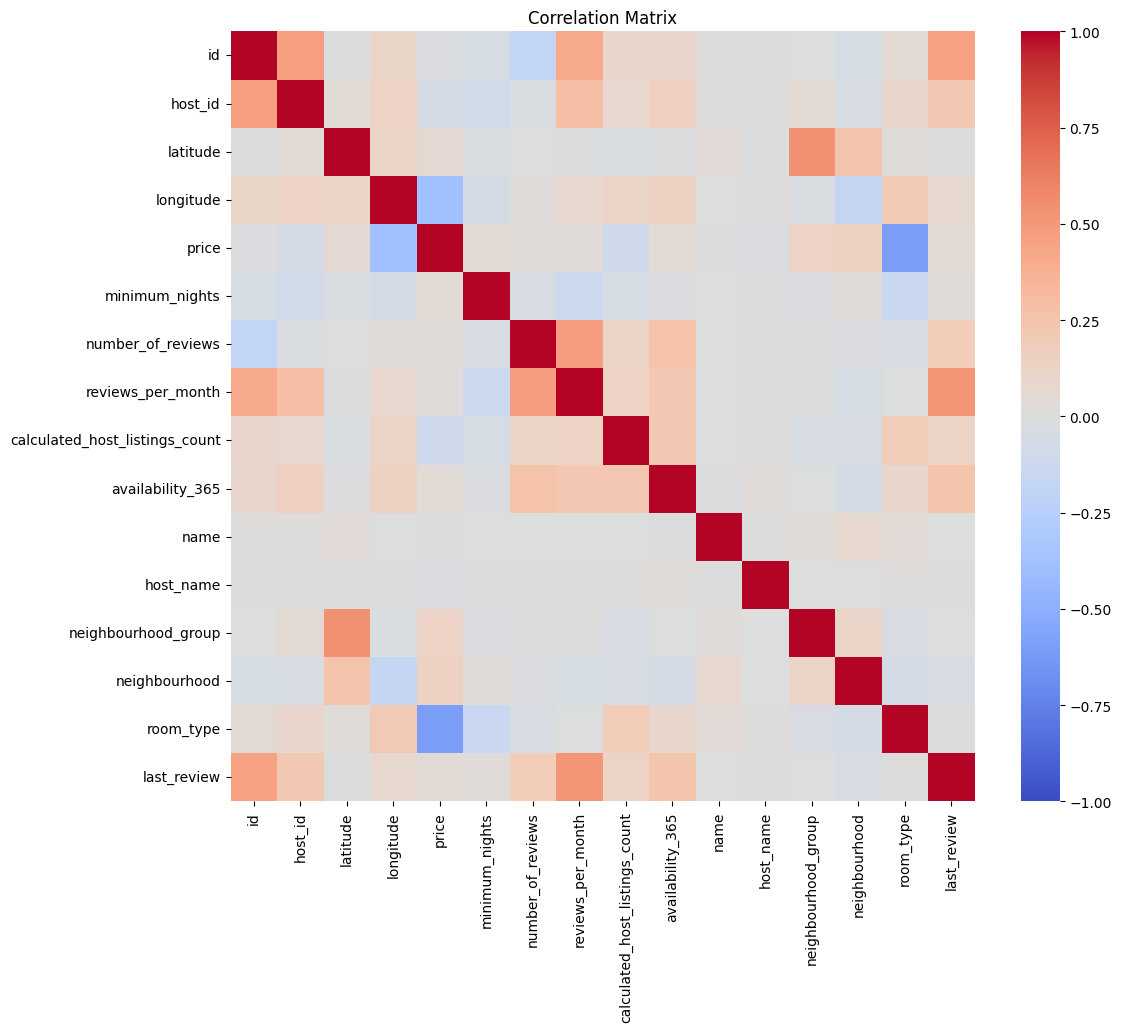

In [67]:
# Visualisasi korelari antar variabel numerik
plt.figure(figsize=(12, 10))
correlation_matrix = df_lencoder.corr()

sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()

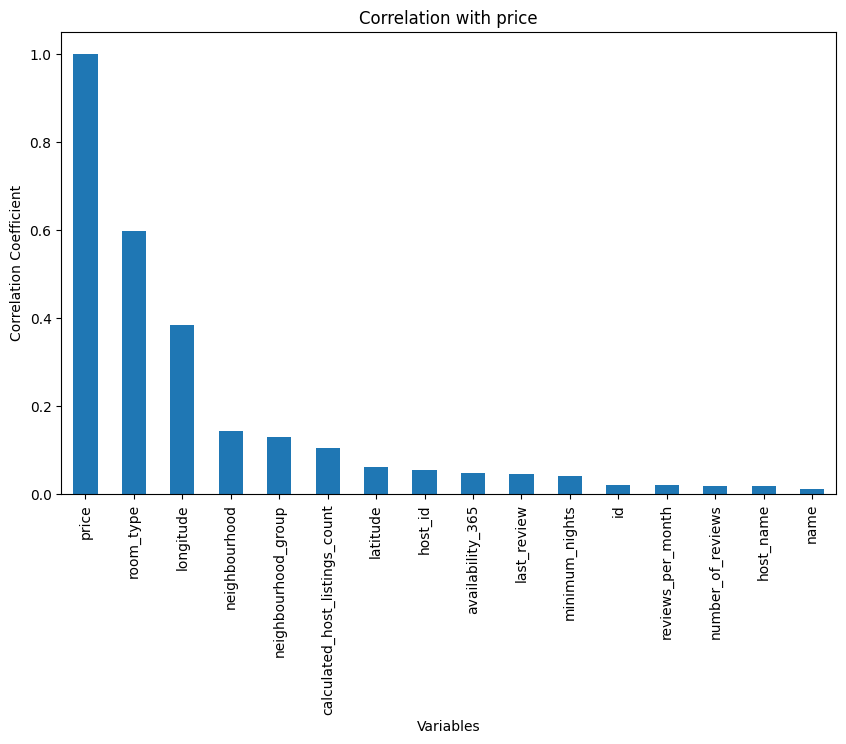

In [68]:
# Menghitung kolerasi antara variabel target dan semua variabel lainnya
target_corr = df_lencoder.corr()['price']

# (Opsional) mengurutkan hasil korelasi berdasarkan korelasi
target_corr_sorted = target_corr.abs().sort_values(ascending=False)

plt.figure(figsize=(10,6))
target_corr_sorted.plot(kind='bar')
plt.title(f'Correlation with price')
plt.xlabel('Variables')
plt.ylabel('Correlation Coefficient')
plt.show()

In [69]:
import sklearn

In [70]:
# Memisahkan fitur (x) dan target (y)
x = df_lencoder.drop(columns=['price'])
y = df_lencoder['price']

In [71]:
from sklearn.model_selection import train_test_split

# membagi dataset menjadi training dan testing
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=1)

In [72]:
# menghitung panjang/jumlah data
print ("Jumlah data:",len(x))
#menghitung panjang/jumlah data pada x_train
print("Jumlah data latih: ",len(x_train))
# menghitung panjang/jumlah data pada x_test
print("Jumlah data test: ",len(x_test))

Jumlah data: 27049
Jumlah data latih:  21639
Jumlah data test:  5410


In [73]:
# MODEL MACHINE LEARNING AIRBNB NYC
# RANDOM FOREST REGRESSOR

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [74]:
# 1. MEMBUAT MODEL

model = RandomForestRegressor(
    n_estimators=100,
    random_state=1,
    n_jobs=-1
)

In [75]:
# 2. TRAINING MODEL

model.fit(x_train, y_train)

print("Model berhasil dilatih!")

Model berhasil dilatih!


In [76]:
# 3. MELAKUKAN PREDIKSI

y_pred = model.predict(x_test)

print("\n10 Hasil Prediksi Pertama:")
print(y_pred[:10])


10 Hasil Prediksi Pertama:
[-0.70026403 -0.59960436  1.07056722  1.08779321  0.94414347  0.21660774
 -0.55331889 -0.11128513 -0.5497239  -0.88555571]


In [77]:
# 4. EVALUASI MODEL

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE  :", mae)
print("RMSE :", rmse)
print("R²   :", r2)

MAE  : 0.5055465380215377
RMSE : 0.6827932268789899
R²   : 0.5295667495788986


In [78]:
# 5. PERBANDINGAN HARGA AKTUAL DAN PREDIKSI

hasil_prediksi = pd.DataFrame({
    'Harga Aktual': y_test.values,
    'Harga Prediksi': y_pred
})

print("PERBANDINGAN HARGA AKTUAL DAN PREDIKSI")
print(hasil_prediksi.head(10))

PERBANDINGAN HARGA AKTUAL DAN PREDIKSI
   Harga Aktual  Harga Prediksi
0     -0.329081       -0.700264
1     -1.122975       -0.599604
2      1.468413        1.070567
3      2.651763        1.087793
4      1.902807        0.944143
5      0.419874        0.216608
6     -0.403977       -0.553319
7      0.869248       -0.111285
8     -1.078037       -0.549724
9     -0.778455       -0.885556


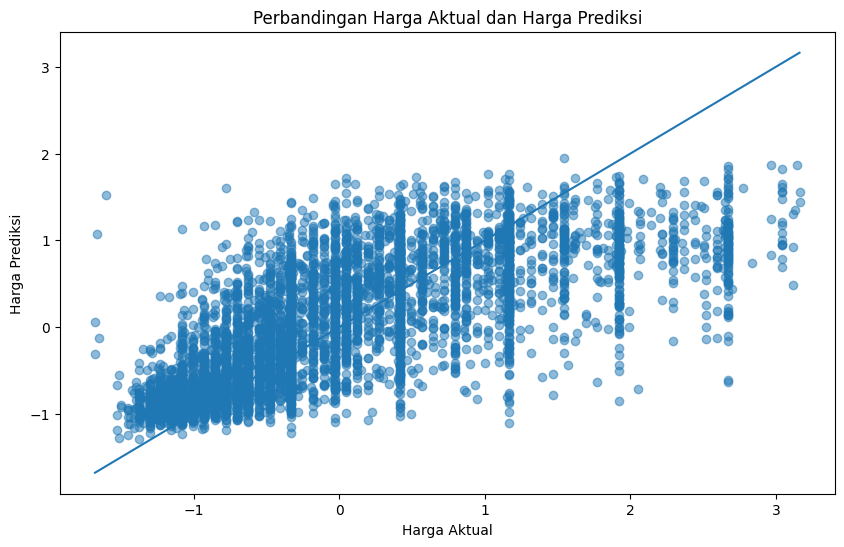

In [79]:
# 6. GRAFIK AKTUAL VS PREDIKSI

plt.figure(figsize=(10, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.5
)

plt.xlabel("Harga Aktual")
plt.ylabel("Harga Prediksi")
plt.title("Perbandingan Harga Aktual dan Harga Prediksi")

# Garis prediksi ideal
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()]
)

plt.show()


In [80]:
# 7. FEATURE IMPORTANCE

feature_importance = pd.DataFrame({
    'Fitur': x_train.columns,
    'Importance': model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("FEATURE IMPORTANCE")

print(feature_importance)



FEATURE IMPORTANCE
                             Fitur  Importance
13                       room_type    0.376939
3                        longitude    0.128270
2                         latitude    0.095409
9                             name    0.057189
1                          host_id    0.051635
10                       host_name    0.050961
8                 availability_365    0.049460
0                               id    0.047223
14                     last_review    0.033922
6                reviews_per_month    0.027663
5                number_of_reviews    0.027618
12                   neighbourhood    0.025013
4                   minimum_nights    0.020446
7   calculated_host_listings_count    0.006698
11             neighbourhood_group    0.001552


<Figure size 1000x600 with 0 Axes>

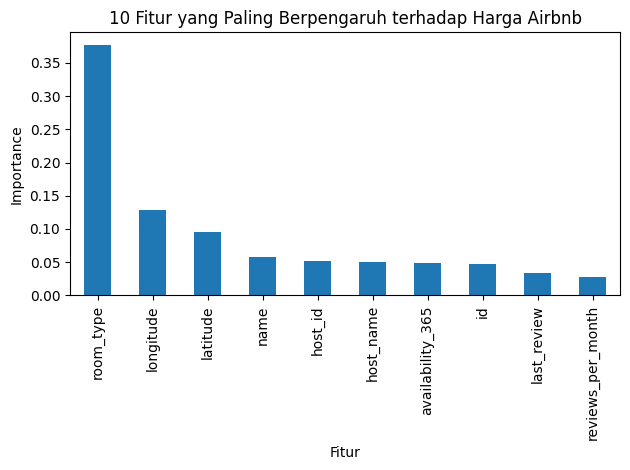

In [81]:
# 8. GRAFIK 10 FITUR TERPENTING

plt.figure(figsize=(10, 6))

feature_importance.head(10).plot(
    x='Fitur',
    y='Importance',
    kind='bar',
    legend=False
)

plt.title(
    "10 Fitur yang Paling Berpengaruh "
    "terhadap Harga Airbnb"
)

plt.xlabel("Fitur")
plt.ylabel("Importance")

plt.tight_layout()
plt.show()

In [82]:
import joblib

# Menyimpan model ke dalam file
joblib.dump(model, 'model_airbnb.joblib')

['model_airbnb.joblib']

In [83]:
import joblib

model = joblib.load('model_airbnb.joblib')